# Раннее выявление риска расторжения: второй подход — детектор аномалий

В основном ноутбуке `churn.ipynb` задача решена **обучением с учителем**: модель (CatBoost) учится
на размеченных уходах. Здесь — **второй подход, без учителя**: детектор аномального поведения.
Правильные ответы (кто ушёл) ему не нужны, он ищет клиентов, чья активность сильно отклонилась
от их собственной нормы.

Зачем второй подход:
- размеченных уходов мало (36 в train) — обучение с учителем на таких данных неустойчиво;
- детектор работает и там, где истории уходов нет совсем (новый продукт, новая база клиентов);
- его решения проще объяснить: «активность клиента упала на 40% от его обычного уровня».

Сравниваем два варианта детектора с CatBoost из первого подхода на тех же valid и test
и по тем же метрикам:
- **правило по личной норме** — оценка риска = среднее падение активности относительно нормы;
- **Isolation Forest** — ансамбль деревьев, который ищет нетипичные сочетания признаков падения активности.

Метки используются только для выбора порога тревоги на valid и для оценки качества

## Загрузка необходимых библиотек

In [1]:
# Общее
import pandas as pd  # работа с датафреймами
import numpy as np  # математика
from matplotlib import pyplot as plt  # графики
import json  # параметры модели первого подхода
import joblib  # загрузка модели первого подхода
import time  # время обучения и прогноза

# МО
from sklearn.ensemble import IsolationForest  # детектор аномалий
from sklearn.metrics import roc_auc_score, average_precision_score  # метрики: roc_auc, pr_auc

# Функции подготовки данных — те же, что в рабочем скрипте
from churn_pipeline import load_data, build_daily, build_features, add_target

pd.set_option('display.max_columns', None)  # вывод всех колонок датасета

In [2]:
rand_state = 42  # фиксируем random_state

HORIZON_DAYS = 28  # горизонт прогноза: расторжение в ближайшие 28 дней
WARNING_MIN_DAYS = 14  # желаемое предупреждение — за 14–28 дней до ухода
TEST_MONTHS = 2  # последние 2 месяца выгрузки — тестовая выборка (как в churn.ipynb)
VALID_MONTHS = 3  # 3 месяца перед ними — валидационная

## Загрузка данных и признаки

Признаки и таргет строим теми же функциями, что в рабочем скрипте `churn_pipeline.py`
(их расчёт подробно разобран в `churn.ipynb`)

In [3]:
clients, api_usage, product_usage = load_data('data/raw')

DATA_START = min(api_usage['date'].min(), product_usage['date'].min())  # начало периода выгрузки
DATA_END = clients['outcome_observed_until'].max()  # конец периода выгрузки

daily = build_daily(clients, api_usage, product_usage, DATA_START, DATA_END)
panel = add_target(build_features(daily, clients, DATA_START), clients)
panel['days_to_churn'] = (panel['churn_date'] - panel['date']).dt.days  # служебная колонка для метрики
panel.shape

(188422, 68)

Делим на выборки так же, как в `churn.ipynb`: границы отсчитываются от конца выгрузки,
между выборками зазор 28 дней

In [4]:
VALID_END = DATA_END - pd.DateOffset(months=TEST_MONTHS)
TRAIN_END = VALID_END - pd.DateOffset(months=VALID_MONTHS)

labeled = panel.dropna(subset=['target']).sort_values(['date', 'client_id'], ignore_index=True)
gap = pd.Timedelta(days=HORIZON_DAYS)

train = labeled[labeled['date'] <= TRAIN_END - gap]
valid = labeled[(labeled['date'] > TRAIN_END) & (labeled['date'] <= VALID_END - gap)]
test = labeled[labeled['date'] > VALID_END]

for name, df in [('train', train), ('valid', valid), ('test', test)]:
    display(f'{name}: {df["date"].min().date()} — {df["date"].max().date()}, строк {df.shape[0]}, '
            f'уходов {df.loc[df["target"] == 1, "client_id"].nunique()}')

'train: 2025-04-29 — 2026-04-02, строк 125820, уходов 36'

'valid: 2026-05-01 — 2026-07-02, строк 22253, уходов 20'

'test: 2026-07-31 — 2026-09-29, строк 11565, уходов 21'

## Метрики

Та же функция, что в `churn.ipynb`:
- ROC-AUC и PR-AUC — по клиенто-дням;
- early_recall — доля ушедших клиентов с тревогой за 14–28 дней до ухода;
- false_alert_rate — доля неушедших клиентов, получивших хотя бы одну тревогу

In [5]:
def metrics(df, y_proba, threshold):
    ROC_AUC = roc_auc_score(df['target'], y_proba)
    PR_AUC = average_precision_score(df['target'], y_proba)

    alerts = df[['client_id', 'target', 'days_to_churn']].assign(alert=y_proba >= threshold)
    churned = alerts[alerts['target'] == 1]
    early = churned[churned['days_to_churn'].between(WARNING_MIN_DAYS, HORIZON_DAYS)]
    retained = alerts[~alerts['client_id'].isin(churned['client_id'])]

    early_recall = early.groupby('client_id')['alert'].any().mean()
    false_alert_rate = retained.groupby('client_id')['alert'].any().mean()

    return ROC_AUC, PR_AUC, early_recall, false_alert_rate

## Подход 2а. Правило по личной норме

Для каждого клиента уже посчитано, во сколько раз его активность за последние 28 дней отличается
от его обычного уровня (признаки `*_vs_norm`, 1 — как обычно). Превратим их в «падение»:
`1 − vs_norm`, отрицательные значения (рост активности) заменим нулём — рост нас не тревожит.

Оценка риска — среднее падение по четырём показателям: запросы, ручки API, сессии, продукты.
Обучения нет совсем — это готовое правило

In [6]:
norm_cols = ['api_requests_vs_norm', 'api_endpoints_vs_norm', 'product_sessions_vs_norm', 'products_used_vs_norm']


def decline_score(df):
    # среднее падение активности относительно личной нормы (0 — нет падения, 1 — активность пропала)
    drops = (1 - df[norm_cols]).clip(lower=0)
    return drops.mean(axis=1).to_numpy()

## Подход 2б. Isolation Forest

Isolation Forest — ансамбль случайных деревьев: чем быстрее деревья «отделяют» строку
от остальных, тем она необычнее. Даём ему только признаки изменения поведения:
- падение активности относительно нормы (как в правиле выше);
- падение за последнюю неделю относительно месяца (из трендов);
- дни без активности по API и продуктам.

Признаки строим так, чтобы большие значения означали «хуже» — иначе лес считал бы аномалией
и резкий рост активности. Обучаем на train **без меток**

In [7]:
trend_cols = ['api_requests_trend_7_28', 'product_sessions_trend_7_28', 'active_days_trend_7_28']


def behaviour_features(df):
    # признаки изменения поведения: больше — хуже
    X = pd.DataFrame(index=df.index)
    for col in norm_cols + trend_cols:
        X[f'{col}_drop'] = (1 - df[col]).clip(lower=0)  # падение, рост не считаем
    X['days_without_api'] = np.log1p(df['days_without_api'])  # логарифм — у некоторых клиентов API нет совсем
    X['days_without_product'] = np.log1p(df['days_without_product'])
    return X

In [8]:
start = time.time()
iso_forest = IsolationForest(n_estimators=300, random_state=rand_state, n_jobs=-1)
iso_forest.fit(behaviour_features(train))  # без меток
fit_time_iso = time.time() - start

display(f'Isolation Forest обучен за {fit_time_iso:.1f} с')

'Isolation Forest обучен за 0.5 с'

## Подход 1. CatBoost из основного ноутбука

Загружаем модель, сохранённую в `churn.ipynb` (обучена на том же train)

In [9]:
with open('models/model_params.json', encoding='utf-8') as f:
    model_params = json.load(f)
model_cb = joblib.load('models/churn_model.pkl')
feature_cols = model_params['feature_cols']

display(f'Модель первого подхода: {model_params["model"]}')

'Модель первого подхода: catboost_optuna'

## Сравнение подходов на valid

У каждого подхода своя шкала оценок, поэтому порог подбираем одинаково для всех:
как квантиль оценки на valid (alert_share — доля клиенто-дней с тревогой).
Лучший порог — максимум разницы early_recall − false_alert_rate, как в `churn.ipynb`

In [10]:
# функция оценки риска для каждого подхода
scorers = {
    f'{model_params["model"]} (с учителем)': lambda df: model_cb.predict_proba(df[feature_cols])[:, 1],
    'правило по норме (без учителя)': decline_score,
    'isolation forest (без учителя)': lambda df: -iso_forest.score_samples(behaviour_features(df))
}

threshold_metrics = []
for name, scorer in scorers.items():
    valid_score = scorer(valid)
    for q in [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.99]:
        t = np.quantile(valid_score, q)
        ROC_AUC, PR_AUC, early_recall, false_alert_rate = metrics(valid, valid_score, t)
        threshold_metrics.append({'approach': name,
                                  'alert_share': round(1 - q, 2),
                                  'threshold': t,
                                  'ROC_AUC': ROC_AUC,
                                  'PR_AUC': PR_AUC,
                                  'early_recall': early_recall,
                                  'false_alert_rate': false_alert_rate})

df_thresholds = pd.DataFrame(threshold_metrics)
display(df_thresholds)

,approach,alert_share,threshold,ROC_AUC,PR_AUC,early_recall,false_alert_rate
0,catboost_optuna (с учителем),0.20,0.320370,0.877903,0.245964,0.866667,0.619186
1,catboost_optuna (с учителем),0.15,0.391501,0.877903,0.245964,0.866667,0.511628
2,catboost_optuna (с учителем),0.10,0.485320,0.877903,0.245964,0.866667,0.360465
3,catboost_optuna (с учителем),0.07,0.607979,0.877903,0.245964,0.800000,0.267442
4,catboost_optuna (с учителем),0.05,0.707475,0.877903,0.245964,0.600000,0.174419
5,catboost_optuna (с учителем),0.03,0.804780,0.877903,0.245964,0.466667,0.087209
6,catboost_optuna (с учителем),0.01,0.900592,0.877903,0.245964,0.200000,0.026163
7,правило по норме (без учителя),0.20,0.108114,0.845481,0.270781,0.866667,0.642442
8,правило по норме (без учителя),0.15,0.132498,0.845481,0.270781,0.866667,0.514535
9,правило по норме (без учителя),0.10,0.166881,0.845481,0.270781,0.733333,0.386628


In [11]:
# лучший порог для каждого подхода
df_thresholds['score'] = df_thresholds['early_recall'] - df_thresholds['false_alert_rate']
best = df_thresholds.loc[df_thresholds.groupby('approach')['score'].idxmax()].set_index('approach')
display(best[['alert_share', 'threshold', 'ROC_AUC', 'PR_AUC', 'early_recall', 'false_alert_rate']])

,alert_share,threshold,ROC_AUC,PR_AUC,early_recall,false_alert_rate
approach,,,,,,
catboost_optuna (с учителем),0.07,0.607979,0.877903,0.245964,0.800000,0.267442
isolation forest (без учителя),0.05,0.599111,0.862558,0.193224,0.733333,0.223837
правило по норме (без учителя),0.05,0.237323,0.845481,0.270781,0.600000,0.165698


**Вывод:** на valid лучше подход с учителем: CatBoost ловит 80% уходов за 14–28 дней
при ложных тревогах у 27% неушедших клиентов (бюджет тревог 7%). Детекторы без учителя
выбрали бюджет 5%: Isolation Forest — 73% уходов и 22% ложных тревог, правило по норме —
60% и 17%. При одинаковом бюджете 7% правило ловит 67% уходов при тех же 26% ложных тревог,
что у CatBoost. По ранжированию (ROC-AUC) подходы близки: 0.878, 0.863 и 0.845

## Сравнение подходов на test

Порог каждого подхода — с valid, test подходы не видели.
Заодно замерим время расчёта оценок на всём test

In [12]:
res = []
test_scores = {}
for name, scorer in scorers.items():
    start = time.time()
    test_score = scorer(test)
    predict_time = time.time() - start
    test_scores[name] = test_score

    ROC_AUC, PR_AUC, early_recall, false_alert_rate = metrics(test, test_score, best.loc[name, 'threshold'])
    res.append({'approach': name,
                'ROC_AUC': ROC_AUC,
                'PR_AUC': PR_AUC,
                'early_recall': early_recall,
                'false_alert_rate': false_alert_rate,
                'predict_time_sec': predict_time})

df_results = pd.DataFrame(res).set_index('approach')
display(df_results)

,ROC_AUC,PR_AUC,early_recall,false_alert_rate,predict_time_sec
approach,,,,,
catboost_optuna (с учителем),0.874664,0.381463,0.722222,0.215625,0.005740
правило по норме (без учителя),0.877268,0.327431,0.777778,0.131250,0.002556
isolation forest (без учителя),0.869850,0.280786,0.722222,0.212500,0.151804


Как меняется оценка риска перед уходом у каждого подхода. Шкалы у подходов разные,
поэтому делим оценку на её средний уровень у оставшихся клиентов: 1 — как у обычного клиента

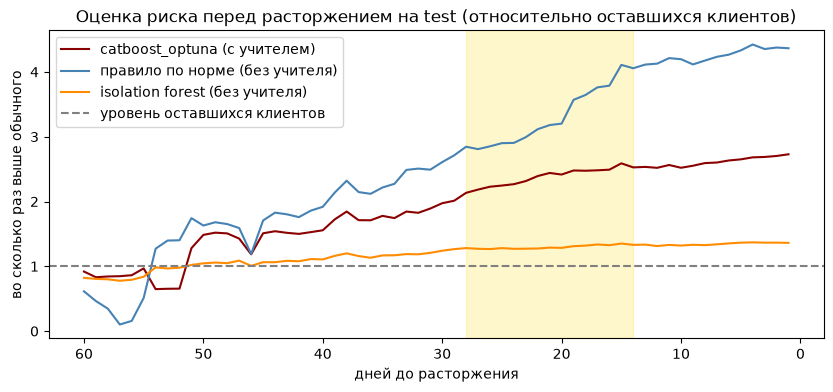

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
for (name, test_score), color in zip(test_scores.items(), ['darkred', 'steelblue', 'darkorange']):
    scored = test.assign(score=test_score)
    retained_level = scored.loc[scored['days_to_churn'].isna(), 'score'].mean()
    before_churn = scored[scored['days_to_churn'] <= 60].groupby('days_to_churn')['score'].mean()
    (before_churn / retained_level).plot(ax=ax, color=color, label=name)

ax.axhline(1, color='gray', linestyle='--', label='уровень оставшихся клиентов')
ax.axvspan(WARNING_MIN_DAYS, HORIZON_DAYS, color='gold', alpha=0.2)
ax.invert_xaxis()
ax.set_title('Оценка риска перед расторжением на test (относительно оставшихся клиентов)')
ax.set_xlabel('дней до расторжения')
ax.set_ylabel('во сколько раз выше обычного')
ax.legend()
plt.show()

Совпадают ли тревоги подходов: каких ушедших клиентов поймал только один из них

In [14]:
early = test[test['days_to_churn'].between(WARNING_MIN_DAYS, HORIZON_DAYS)]

caught = pd.DataFrame(index=early['client_id'].unique())
for name, test_score in test_scores.items():
    scored = test.assign(score=test_score)
    scored_early = scored[scored['days_to_churn'].between(WARNING_MIN_DAYS, HORIZON_DAYS)]
    caught[name] = scored_early.groupby('client_id')['score'].max() >= best.loc[name, 'threshold']

caught['хоть одним'] = caught.any(axis=1)
display(caught.sort_values(list(scorers)))
display(caught.mean())

,catboost_optuna (с учителем),правило по норме (без учителя),isolation forest (без учителя),хоть одним
C034,False,False,False,False
C324,False,False,False,False
C157,False,False,False,False
C078,False,True,True,True
C181,False,True,True,True
C023,True,False,False,True
C042,True,True,False,True
C028,True,True,True,True
C073,True,True,True,True
C276,True,True,True,True


catboost_optuna (с учителем)      0.722222
правило по норме (без учителя)    0.777778
isolation forest (без учителя)    0.722222
хоть одним                        0.833333
dtype: float64

**Вывод:** на test картина обратная: правило по норме не хуже CatBoost по ROC-AUC (0.877 против 0.875),
ловит больше уходов за 14–28 дней (78% против 72%) и даёт вдвое меньше ложных тревог (13% против 22%).
Isolation Forest — на уровне CatBoost по пойманным уходам (72%) и ложным тревогам (21%).
CatBoost лучше остальных по PR-AUC (0.381): его самые высокие оценки точнее указывают на уход.

Разница между valid и test — один-два клиента при 15–18 уходах в выборке, поэтому честный вывод:
**подходы сопоставимы по качеству**, ни один не выигрывает устойчиво.

Подходы частично ловят разных клиентов: двух ушедших (C078, C181) заметили только детекторы
без учителя, одного (C023) — только CatBoost. Вместе они ловят 83% уходов (15 из 18).
Трёх клиентов (C034, C324, C157) не поймал ни один подход — перед уходом их активность
заметно не падала, по поведению этот уход не предсказать.

По скорости все подходы мгновенные (доли секунды на 11,5 тыс. строк). Обучение Isolation Forest —
меньше секунды, правилу обучение не нужно вовсе; CatBoost требует размеченных уходов
и нескольких минут на подбор параметров

## Выводы по второму подходу

1. **Второй подход — детектор аномального поведения без учителя** — реализован в двух вариантах:
   правило по личной норме клиента и Isolation Forest на признаках падения активности.
   Метки уходов использовались только для выбора порога на valid и для оценки качества.

2. **Качество сопоставимо с обучением с учителем.** На test: правило по норме — ROC-AUC 0.877,
   78% уходов за 14–28 дней, 13% ложных тревог; CatBoost — 0.875, 72% и 22%; Isolation Forest —
   0.870, 72% и 21%. На valid лучше был CatBoost. Различия в пределах одного-двух клиентов.

3. **Почему простое правило работает так хорошо.** Главный сигнал оттока в этих данных — падение
   активности относительно собственного уровня клиента. Правило измеряет ровно его, а модель с учителем
   на 36 уходах в train выучивает этот же сигнал с дополнительным шумом.

4. **Рекомендация.**
   - Основная оценка риска — CatBoost: она точнее в самом верху списка (PR-AUC 0.381)
     и учитывает доступы и срок договора.
   - Правило по норме — как понятное объяснение для менеджера («активность упала на N% от обычной»)
     и как запасной вариант там, где размеченных уходов нет: новый продукт, новая база клиентов.
   - Тревога по любому из подходов ловит 83% уходов, но ложных тревог при этом будет больше —
     такое объединение стоит проверить на реальных данных.

5. **Ограничения.** Синтетические данные и мало уходов в каждой выборке; часть уходов
   (3 из 18 на test) не сопровождается падением активности и не ловится ни одним подходом.